In [1]:
import numpy as np
import matplotlib.pyplot as plt

# from scipy.ndimage import affine_transform

### my modules
from fast_volume_align_ot import utils, plots, transforms, distances, signals

In [2]:
def rotate_voxel_zyz(voxels, omega, theta, phi, order=1):
    """
    Rotate a 3D voxel array using ZYZ Euler angles.
    order : Interpolation order (0=nearest, 1=linear, etc.) for affine_transform.
    """
    # Compute rotation matrix
    Rz1 = transforms.rotate_z(omega)
    Ry = transforms.rotate_y(theta)
    Rz2 = transforms.rotate_z(phi)
    R = Rz1 @ Ry @ Rz2

    # Center of the volume
    center = np.array(voxels.shape) / 2.0

    # Affine transform expects the inverse rotation
    R_inv = np.linalg.inv(R)

    # Compute offset so rotation is about the center
    offset = center - R_inv @ center

    # Apply affine transform
    rotated = affine_transform(
        voxels,
        R_inv,
        offset=offset,
        order=order,
        mode='constant',
        cval=0.0
    )
    return rotated

In [3]:
L = 65
sigma = 2

f = utils.generate_3d_triangle_gaussian_shape(L, sigma, rescale=True)

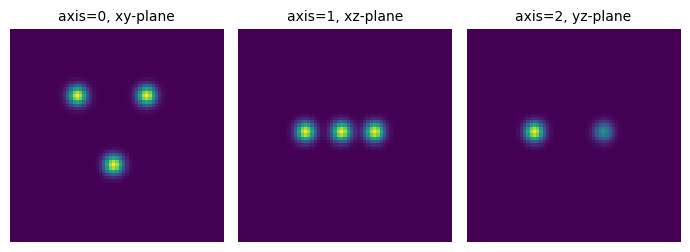

In [4]:
plots.orthogonal_2D_projection_plot(f)

In [5]:
omega = -np.deg2rad(10)
theta = -np.deg2rad(49)
phi = -np.deg2rad(298)

# f_rotate = rotate_voxel_zyz(f, omega, theta, phi, order=1)
f_rotate = transforms.rotate_voxel_zyz(f, omega, theta, phi, order=1)

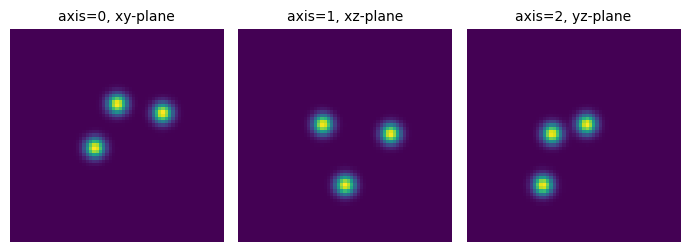

In [6]:
plots.orthogonal_2D_projection_plot(f_rotate)

In [8]:
# g = rotate_voxel_zyz(f_rotate, -phi, -theta, -omega, order=1)
g = transforms.rotate_voxel_zyz(f_rotate, -phi, -theta, -omega, order=1)

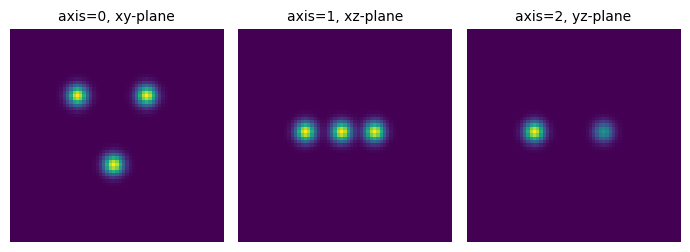

In [9]:
plots.orthogonal_2D_projection_plot(g)

In [10]:
np.allclose(f, g)

False

In [11]:
np.linalg.norm(f - g)

np.float64(0.15993250991174118)

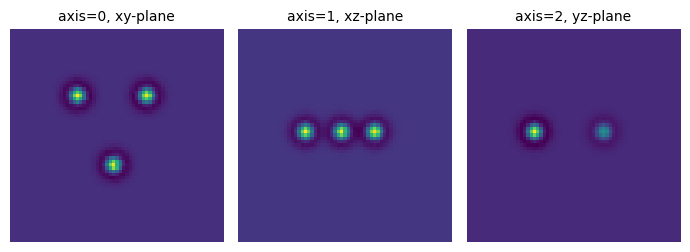

In [12]:
plots.orthogonal_2D_projection_plot(f - g)